29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
=== EDA SUMMARY FOR FASHION_MNIST ===
Training images shape : (60000, 28, 28) | dtype: uint8
Training labels shape : (60000,) | dtype: uint8
Test images shape     : (10000, 28, 28) | dtype: uint8
Test labels shape     : (10000,) | dtype: uint8
Number of classes     : 10 ([0 1 2 3 4 5 6 7 8 9])

--- Data Integrity Checks ---
NaN values in X_train : False
NaN values in y_train : False
Completely black imgs : 0

--- Pixel Intensity Statistics (Raw) ---
Min pixel value       : 0
Max pixel value       : 255
Global Mean           : 72.94
Global Std Dev        : 90.02


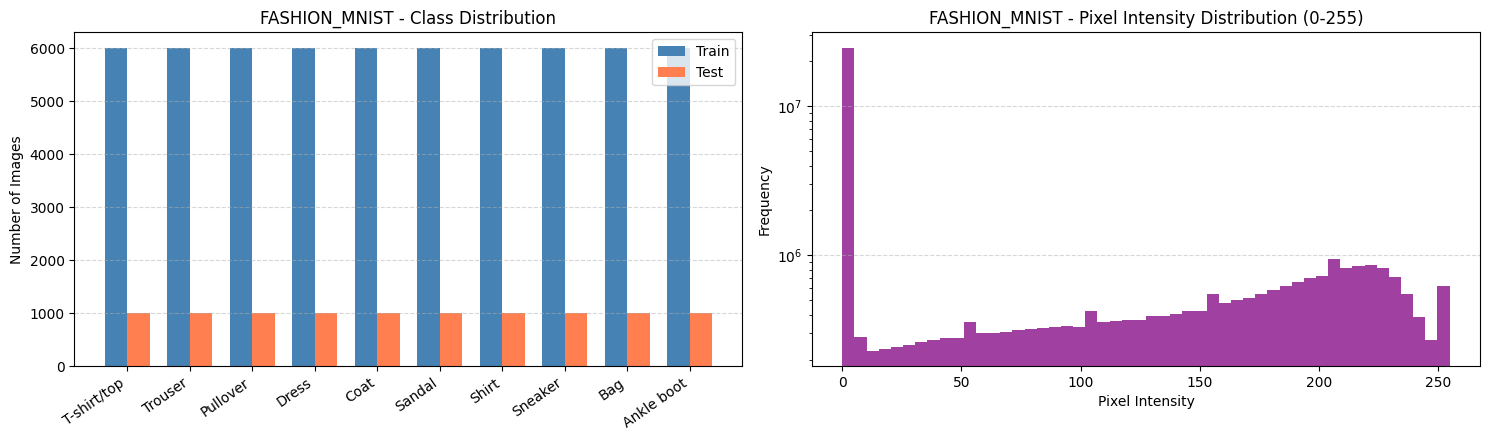

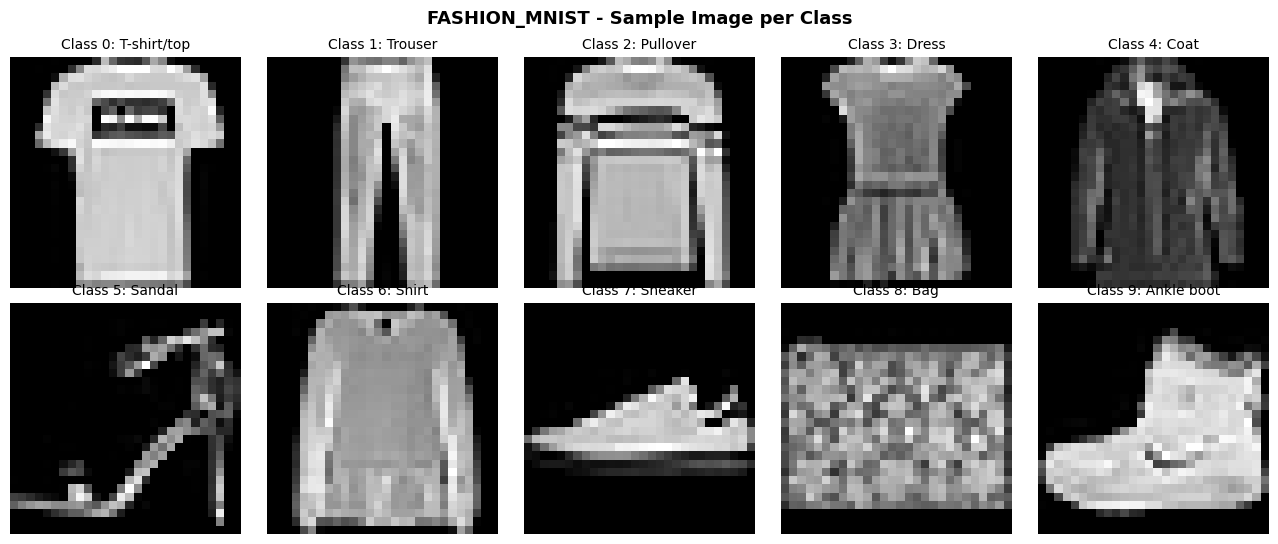

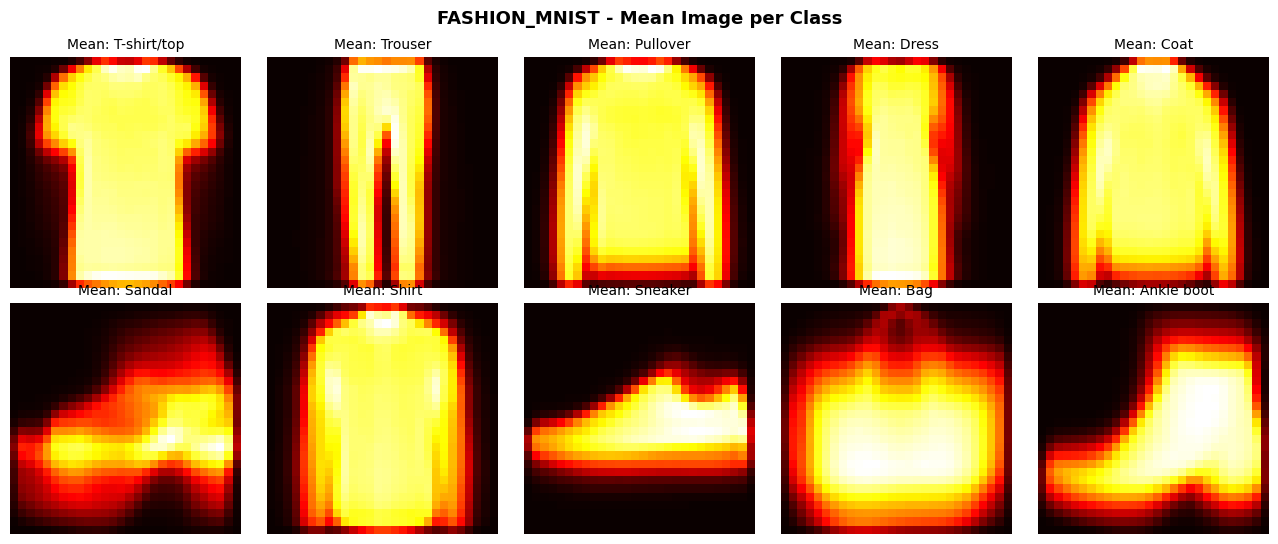


--- Ready for CNN Training ---
Normalized X_train shape: (60000, 28, 28, 1) | range: [0.0, 1.0]
Normalized X_test shape : (10000, 28, 28, 1) | range: [0.0, 1.0]


In [1]:

# ==============================================================================
# Complete Image Dataset EDA Pipeline for Google Colab
# Supports: "mnist", "fashion_mnist", and "cifar10"
# ==============================================================================

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist, fashion_mnist, cifar10

# 1. SELECT DATASET ("mnist", "fashion_mnist", or "cifar10")
DATASET_NAME = "fashion_mnist"

def load_selected_dataset(name):
    if name == "mnist":
        (X_train, y_train), (X_test, y_test) = mnist.load_data()
        classes = [str(i) for i in range(10)]
    elif name == "fashion_mnist":
        (X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()
        classes = [
            "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
            "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
        ]
    elif name == "cifar10":
        (X_train, y_train), (X_test, y_test) = cifar10.load_data()
        classes = [
            "Airplane", "Automobile", "Bird", "Cat", "Deer",
            "Dog", "Frog", "Horse", "Ship", "Truck"
        ]
    else:
        raise ValueError("Choose 'mnist', 'fashion_mnist', or 'cifar10'")

    return X_train, y_train.flatten(), X_test, y_test.flatten(), classes

X_train, y_train, X_test, y_test, class_names = load_selected_dataset(DATASET_NAME)
is_color = (X_train.ndim == 4)

# ==============================================================================
# 2. BASIC SHAPE, DATA TYPE & INTEGRITY CHECKS
# ==============================================================================
print(f"=== EDA SUMMARY FOR {DATASET_NAME.upper()} ===")
print(f"Training images shape : {X_train.shape} | dtype: {X_train.dtype}")
print(f"Training labels shape : {y_train.shape} | dtype: {y_train.dtype}")
print(f"Test images shape     : {X_test.shape} | dtype: {X_test.dtype}")
print(f"Test labels shape     : {y_test.shape} | dtype: {y_test.dtype}")
print(f"Number of classes     : {len(np.unique(y_train))} ({np.unique(y_train)})")

# Missing / corrupted / duplicate checks
print("\n--- Data Integrity Checks ---")
print(f"NaN values in X_train : {np.isnan(X_train).any()}")
print(f"NaN values in y_train : {np.isnan(y_train).any()}")
blank_count = np.sum(X_train.reshape(len(X_train), -1).sum(axis=1) == 0)
print(f"Completely black imgs : {blank_count}")

# ==============================================================================
# 3. PIXEL INTENSITY STATISTICS
# ==============================================================================
print("\n--- Pixel Intensity Statistics (Raw) ---")
print(f"Min pixel value       : {X_train.min()}")
print(f"Max pixel value       : {X_train.max()}")
print(f"Global Mean           : {X_train.mean():.2f}")
print(f"Global Std Dev        : {X_train.std():.2f}")

if is_color:
    channel_means = X_train.mean(axis=(0, 1, 2))
    channel_stds = X_train.std(axis=(0, 1, 2))
    print(f"RGB Channel Means     : R={channel_means[0]:.2f}, G={channel_means[1]:.2f}, B={channel_means[2]:.2f}")
    print(f"RGB Channel Std Devs  : R={channel_stds[0]:.2f}, G={channel_stds[1]:.2f}, B={channel_stds[2]:.2f}")

# ==============================================================================
# 4. CLASS DISTRIBUTION & PIXEL HISTOGRAM PLOTS
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# Plot A: Class Distribution (Train vs Test)
train_counts = np.bincount(y_train)
test_counts = np.bincount(y_test)
x_pos = np.arange(len(class_names))

axes[0].bar(x_pos - 0.18, train_counts, width=0.36, label="Train", color="steelblue")
axes[0].bar(x_pos + 0.18, test_counts, width=0.36, label="Test", color="coral")
axes[0].set_title(f"{DATASET_NAME.upper()} - Class Distribution")
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(class_names, rotation=35, ha="right")
axes[0].set_ylabel("Number of Images")
axes[0].legend()
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

# Plot B: Pixel Intensity Histogram
if is_color:
    colors = ["red", "green", "blue"]
    for c_idx, col in enumerate(colors):
        axes[1].hist(
            X_train[..., c_idx].ravel(), bins=50, color=col,
            alpha=0.45, label=f"{col.upper()} channel"
        )
    axes[1].legend()
else:
    axes[1].hist(X_train.ravel(), bins=50, color="purple", alpha=0.75)
    axes[1].set_yscale("log")  # Log scale highlights non-zero pixel frequencies

axes[1].set_title(f"{DATASET_NAME.upper()} - Pixel Intensity Distribution (0-255)")
axes[1].set_xlabel("Pixel Intensity")
axes[1].set_ylabel("Frequency")
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# ==============================================================================
# 5. SAMPLE IMAGES GRID (1 PER CLASS)
# ==============================================================================
fig, axes = plt.subplots(2, 5, figsize=(13, 5.5))
for idx, ax in enumerate(axes.flat):
    sample_idx = np.where(y_train == idx)[0][0]
    if is_color:
        ax.imshow(X_train[sample_idx])
    else:
        ax.imshow(X_train[sample_idx], cmap="gray")
    ax.set_title(f"Class {idx}: {class_names[idx]}", fontsize=10)
    ax.axis("off")

plt.suptitle(f"{DATASET_NAME.upper()} - Sample Image per Class", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# ==============================================================================
# 6. AVERAGE (MEAN) IMAGE PER CLASS (SPATIAL VARIANCE)
# ==============================================================================
fig, axes = plt.subplots(2, 5, figsize=(13, 5.5))
for idx, ax in enumerate(axes.flat):
    mean_img = X_train[y_train == idx].mean(axis=0)
    if is_color:
        ax.imshow(mean_img.astype("uint8"))
    else:
        ax.imshow(mean_img, cmap="hot")
    ax.set_title(f"Mean: {class_names[idx]}", fontsize=10)
    ax.axis("off")

plt.suptitle(f"{DATASET_NAME.upper()} - Mean Image per Class", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# ==============================================================================
# 7. PREPROCESSING / NORMALIZATION FOR MODEL TRAINING
# ==============================================================================
X_train_norm = X_train.astype("float32") / 255.0
X_test_norm = X_test.astype("float32") / 255.0

# Add explicit channel dimension for grayscale images so shape becomes (N, 28, 28, 1)
if not is_color:
    X_train_norm = np.expand_dims(X_train_norm, axis=-1)
    X_test_norm = np.expand_dims(X_test_norm, axis=-1)

print("\n--- Ready for CNN Training ---")
print(f"Normalized X_train shape: {X_train_norm.shape} | range: [{X_train_norm.min()}, {X_train_norm.max()}]")
print(f"Normalized X_test shape : {X_test_norm.shape} | range: [{X_test_norm.min()}, {X_test_norm.max()}]")